Source File              | Entropy (Bits) | Bit % (0/1)    | Chi2 Stat  | p-value  | Serial Corr
-----------------------------------------------------------------------------------------------
urandom_1mb.bin          | 7.999817       | 49.99%/50.01%  | 265.58     | 0.3115   | 0.000105   
openssl_1mb.bin          | 7.999833       | 50.00%/50.00%  | 242.31     | 0.7060   | 0.000722   
windows_dotnet_1mb.bin   | 7.999782       | 49.98%/50.02%  | 317.43     | 0.0047   | -0.001047  




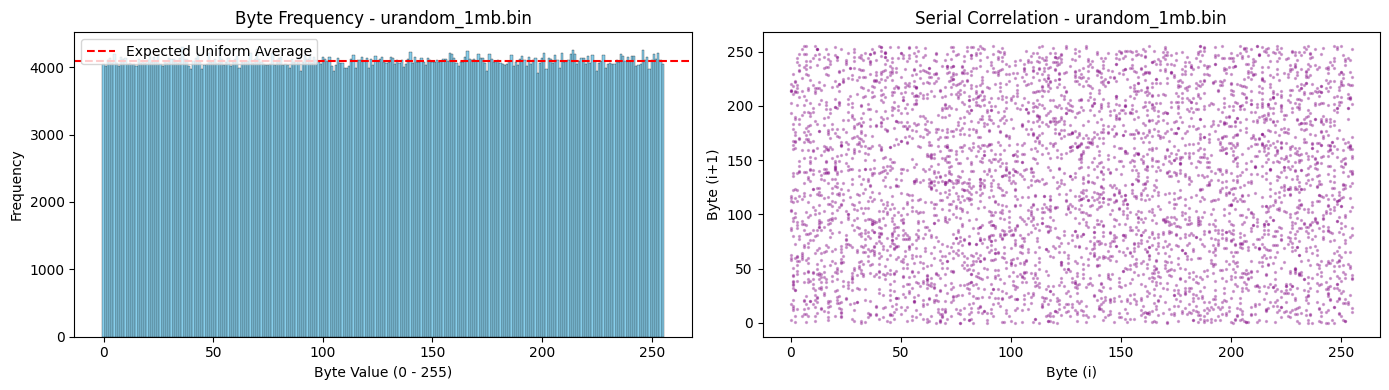

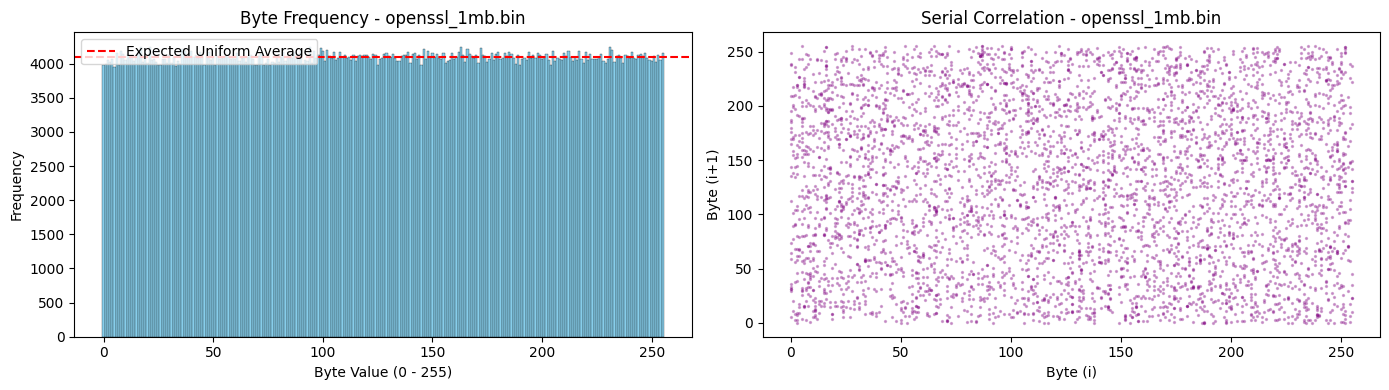

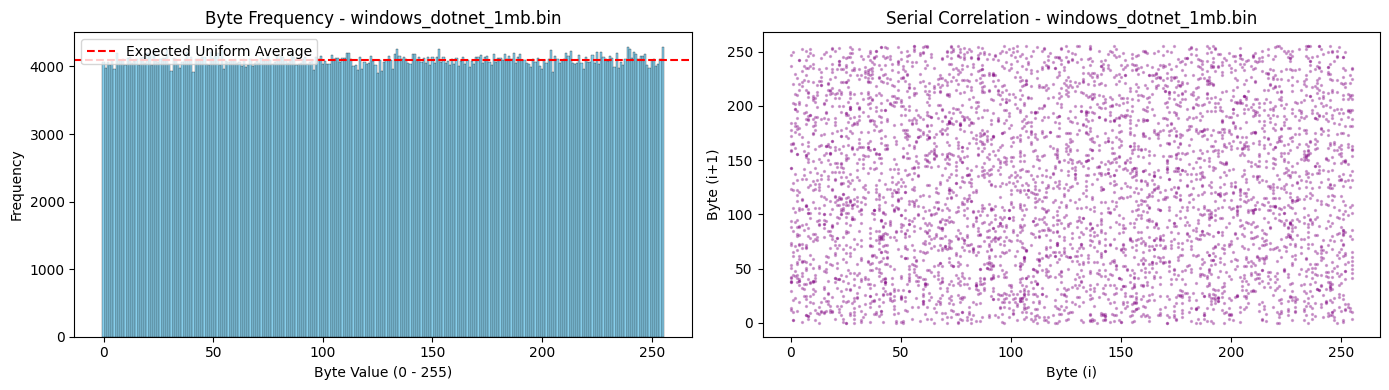

In [2]:
import math
from collections import Counter
import scipy.stats as stats
import matplotlib.pyplot as plt

FILES = [
    "urandom_1mb.bin",
    "openssl_1mb.bin",
    "windows_dotnet_1mb.bin"
]

def calculate_entropy(data):
    if not data:
        return 0.0
    length = len(data)
    counts = Counter(data)
    entropy = 0.0
    for count in counts.values():
        p = count / length
        entropy -= p * math.log2(p)
    return entropy

def calculate_bit_distribution(data):
    total_bits = len(data) * 8
    ones = sum(bin(byte).count('1') for byte in data)
    zeros = total_bits - ones
    return (zeros / total_bits) * 100, (ones / total_bits) * 100

def calculate_chi_square(data):
    counts = Counter(data)
    observed = [counts[i] for i in range(256)]
    expected = [len(data) / 256.0] * 256
    chi2_stat, p_value = stats.chisquare(f_obs=observed, f_exp=expected)
    return chi2_stat, p_value

def calculate_serial_correlation(data):
    n = len(data)
    if n <= 1:
        return 0.0
    
    x = list(data[:-1])
    y = list(data[1:])
    
    mean_x = sum(x) / len(x)
    mean_y = sum(y) / len(y)
    
    num = sum((x[i] - mean_x) * (y[i] - mean_y) for i in range(len(x)))
    den_x = math.sqrt(sum((x[i] - mean_x) ** 2 for i in range(len(x))))
    den_y = math.sqrt(sum((y[i] - mean_y) ** 2 for i in range(len(x))))
    
    if den_x * den_y == 0:
        return 0.0
    return num / (den_x * den_y)

def display_plots(filename, data):
    counts = Counter(data)
    byte_values = list(range(256))
    frequencies = [counts[i] for i in byte_values]

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    # 1. Byte Frequency Plot
    axes[0].bar(byte_values, frequencies, width=1.0, color='skyblue', edgecolor='black', linewidth=0.2)
    axes[0].axhline(y=len(data)/256.0, color='r', linestyle='--', label='Expected Uniform Average')
    axes[0].set_title(f'Byte Frequency - {filename}')
    axes[0].set_xlabel('Byte Value (0 - 255)')
    axes[0].set_ylabel('Frequency')
    axes[0].legend()

    # 2. Serial Correlation Scatter Plot
    sample_size = min(5000, len(data) - 1)
    x = list(data[:sample_size])
    y = list(data[1:sample_size + 1])

    axes[1].scatter(x, y, alpha=0.3, s=2, color='purple')
    axes[1].set_title(f'Serial Correlation - {filename}')
    axes[1].set_xlabel('Byte (i)')
    axes[1].set_ylabel('Byte (i+1)')

    plt.tight_layout()
    plt.show()

# --- EXECUTION ---
results = []

# Step 1: Compute metrics for all files first
for filename in FILES:
    try:
        with open(filename, "rb") as f:
            data = f.read()
        
        entropy = calculate_entropy(data)
        zero_pct, one_pct = calculate_bit_distribution(data)
        chi2_stat, p_val = calculate_chi_square(data)
        serial_corr = calculate_serial_correlation(data)
        
        results.append({
            'filename': filename,
            'data': data,
            'entropy': entropy,
            'zero_pct': zero_pct,
            'one_pct': one_pct,
            'chi2_stat': chi2_stat,
            'p_val': p_val,
            'serial_corr': serial_corr
        })
    except FileNotFoundError:
        print(f"File {filename} not found.")

# Step 2: Print the ENTIRE table at the top
print(f"{'Source File':<24} | {'Entropy (Bits)':<14} | {'Bit % (0/1)':<14} | {'Chi2 Stat':<10} | {'p-value':<8} | {'Serial Corr':<11}")
print("-" * 95)
for res in results:
    bit_str = f"{res['zero_pct']:.2f}%/{res['one_pct']:.2f}%"
    print(f"{res['filename']:<24} | {res['entropy']:<14.6f} | {bit_str:<14} | {res['chi2_stat']:<10.2f} | {res['p_val']:<8.4f} | {res['serial_corr']:<11.6f}")

print("\n" + "="*95 + "\n")

# Step 3: Render all plots underneath the table
for res in results:
    display_plots(res['filename'], res['data'])